1. Membaca dataset

In [2]:
import pandas as pd

data_buku = pd.read_csv("D:/SISTEM-rekomendasi-SEM5/Recommender-System/dataset/Books.csv", low_memory=False)
data_rating = pd.read_csv("D:/SISTEM-rekomendasi-SEM5/Recommender-System/dataset/Ratings.csv")
data_user = pd.read_csv("D:/SISTEM-rekomendasi-SEM5/Recommender-System/dataset/Users.csv")

print("1. Data buku")
display(data_buku)
print("2. Data rating")
display(data_rating)
print("3. Data user")
display(data_user)

1. Data buku


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...
...,...,...,...,...,...,...,...,...
271355,0440400988,There's a Bat in Bunk Five,Paula Danziger,1988,Random House Childrens Pub (Mm),http://images.amazon.com/images/P/0440400988.0...,http://images.amazon.com/images/P/0440400988.0...,http://images.amazon.com/images/P/0440400988.0...
271356,0525447644,From One to One Hundred,Teri Sloat,1991,Dutton Books,http://images.amazon.com/images/P/0525447644.0...,http://images.amazon.com/images/P/0525447644.0...,http://images.amazon.com/images/P/0525447644.0...
271357,006008667X,Lily Dale : The True Story of the Town that Ta...,Christine Wicker,2004,HarperSanFrancisco,http://images.amazon.com/images/P/006008667X.0...,http://images.amazon.com/images/P/006008667X.0...,http://images.amazon.com/images/P/006008667X.0...
271358,0192126040,Republic (World's Classics),Plato,1996,Oxford University Press,http://images.amazon.com/images/P/0192126040.0...,http://images.amazon.com/images/P/0192126040.0...,http://images.amazon.com/images/P/0192126040.0...


2. Data rating


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6
...,...,...,...
1149775,276704,1563526298,9
1149776,276706,0679447156,0
1149777,276709,0515107662,10
1149778,276721,0590442449,10


3. Data user


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN
...,...,...,...
278853,278854,"portland, oregon, usa",NaN
278854,278855,"tacoma, washington, united kingdom",50.0
278855,278856,"brampton, ontario, canada",NaN
278856,278857,"knoxville, tennessee, usa",NaN


2. Data understanding

In [3]:
data_buku.isnull().sum()

ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

In [4]:
data_buku.shape

(271360, 8)

In [ ]:
data_buku.nunique()

ISBN                   271360
Book-Title             242135
Book-Author            102022
Year-Of-Publication       118
Publisher               16807
Image-URL-S            271044
Image-URL-M            271044
Image-URL-L            271041
dtype: int64

In [6]:
# this means there is more than one ISBN number for a book
data_buku.groupby("Book-Title").agg({"ISBN":"count"}).sort_values("ISBN", ascending=False).head(10)

,ISBN
Book-Title,
Selected Poems,27
Little Women,24
Wuthering Heights,21
Dracula,20
Adventures of Huckleberry Finn,20
The Secret Garden,20
Jane Eyre,19
The Night Before Christmas,18
Pride and Prejudice,18


In [7]:
# combine these two dataframes
merged_df=data_buku.merge(data_rating, how="left", on="ISBN")

In [8]:
# we see that the presentage of 0 given to some books s quite high.
merged_df["Book-Rating"].value_counts()

Book-Rating
0.0     647294
8.0      91804
10.0     71225
7.0      66402
9.0      60778
5.0      45355
6.0      31687
4.0       7617
3.0       5118
2.0       2375
1.0       1481
Name: count, dtype: int64

In [9]:
# How many books has a user commented? let's look at the 10 users who commented the most
merged_df.groupby("User-ID").agg({"Book-Title":"count"}).sort_values("Book-Title",ascending=False).head(10)

,Book-Title
User-ID,
11676.0,11144
198711.0,6456
153662.0,5814
98391.0,5779
35859.0,5646
212898.0,4289
278418.0,3996
76352.0,3329
110973.0,2971


In [11]:
# What are the most comment
merged_df.groupby("Book-Title").agg({"Book-Rating":"count"}).sort_values("Book-Rating", ascending=False).head(5) 

,Book-Rating
Book-Title,
Wild Animus,2502
The Lovely Bones: A Novel,1295
The Da Vinci Code,898
A Painted House,838
The Nanny Diaries: A Novel,828


In [12]:
new=merged_df.groupby("Book-Title").agg({"Book-Rating":["count","mean"]}) 
new.head(5)

Book-Rating      
                                                         count  mean
Book-Title                                                          
A Light in the Storm: The Civil War Diary of Am...           4  2.25
Always Have Popsicles                                        1  0.00
Apple Magic (The Collector's series)                         1  0.00
Ask Lily (Young Women of Faith: Lily Series, Bo...           1  8.00
Beyond IBM: Leadership Marketing and Finance fo...           1  0.00

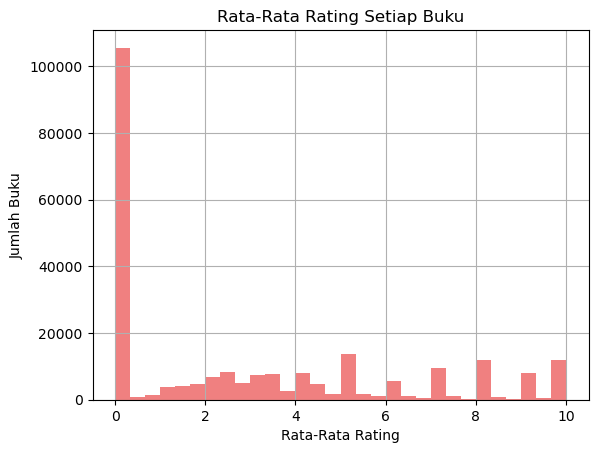

In [17]:
rata_rating_per_buku = merged_df.groupby('Book-Title')['Book-Rating'].mean()
rata_rating_per_buku.hist(bins=30, color='lightcoral')

plt.title('Rata-Rata Rating Setiap Buku')
plt.xlabel('Rata-Rata Rating')
plt.ylabel('Jumlah Buku')
plt.show()

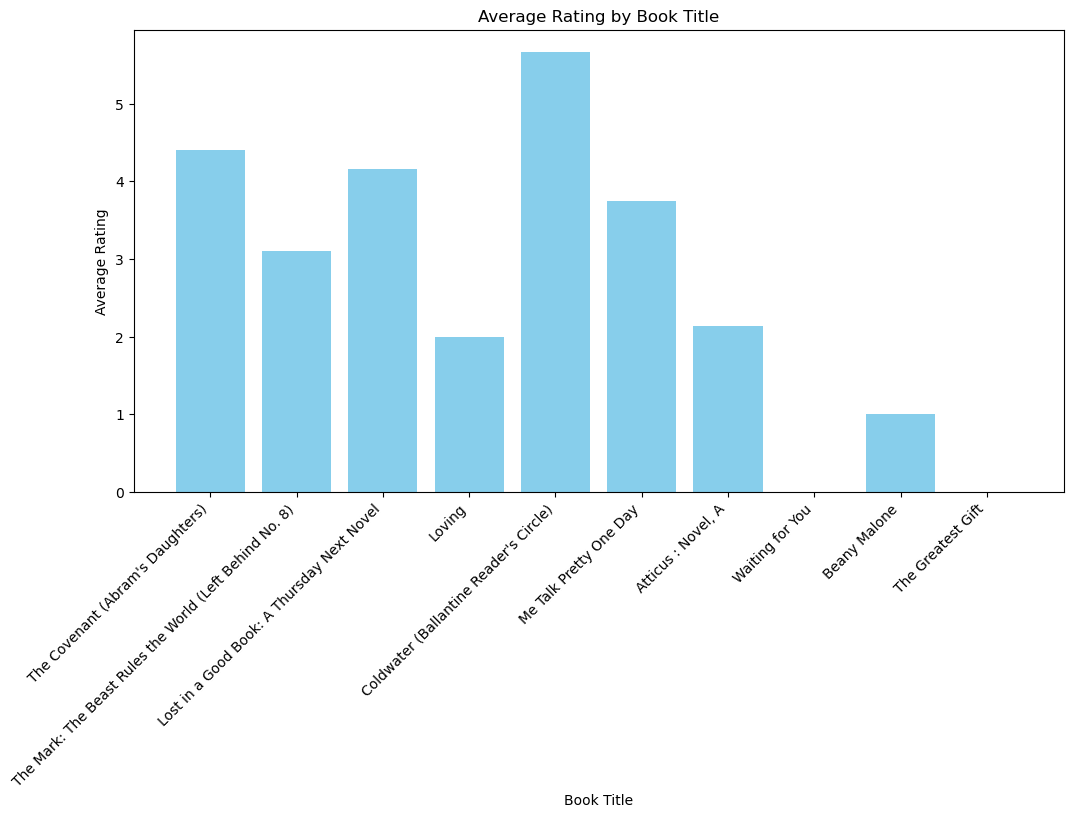

In [16]:
import matplotlib.pyplot as plt
import numpy as np

sample_book = merged_df['Book-Title'].sample(10)
average_ratings = [merged_df[merged_df['Book-Title'] == book]['Book-Rating'].mean() for book in sample_book]

plt.figure(figsize=(12, 6))
plt.bar(sample_book, average_ratings, color='skyblue')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Book Title')
plt.ylabel('Average Rating')
plt.title('Average Rating by Book Title')


plt.show()

In [18]:
merged_df[merged_df["Book-Title"]=="The Open Door"][["Book-Rating"]]

,Book-Rating
912250,0.0


In [19]:
baru = merged_df.groupby("Book-Title").agg({"Book-Rating": ["count", "mean"]})

baru = baru.droplevel(0, axis=1)

baru.head()

,count,mean
Book-Title,,
"A Light in the Storm: The Civil War Diary of Amelia Martin, Fenwick Island, Delaware, 1861 (Dear America)",4,2.25
Always Have Popsicles,1,0.00
Apple Magic (The Collector's series),1,0.00
"Ask Lily (Young Women of Faith: Lily Series, Book 5)",1,8.00
Beyond IBM: Leadership Marketing and Finance for the 1990s,1,0.00


In [20]:
baru[baru["mean"]<2][["count"]].sort_values("count",ascending=False).head(10)

,count
Book-Title,
Wild Animus,2502
Slow Waltz in Cedar Bend,248
Songs in Ordinary Time (Oprah's Book Club (Paperback)),232
Primary Colors: A Novel of Politics,166
The Cardinal of the Kremlin (Jack Ryan Novels),166
Moo,159
The Reef,154
The Burden of Proof,153
4 Blondes,151


In [21]:
# Menampilkan 10 rating pertama dari buku Wild Animus
merged_df[merged_df["Book-Title"] == "Wild Animus"][["Book-Rating"]].head(10)

,Book-Rating
769,0.0
770,0.0
771,0.0
772,2.0
773,0.0
774,0.0
775,0.0
776,0.0
777,0.0
778,0.0


In [22]:
df_baru = pd.DataFrame(merged_df["Book-Title"].value_counts())

In [26]:
buku_terpilih = df_baru[df_baru["count"]<200].index

In [27]:
df_umum = merged_df[~merged_df["Book-Title"].isin(buku_terpilih)]

In [30]:
tabel_rating_pengguna = df_umum.pivot_table(
    index=["User-ID"],
    columns=["Book-Title"],
    values="Book-Rating"
)

In [43]:
import random

pengguna_acak = random.choice(tabel_rating_pengguna.index)
print(pengguna_acak)

26354.0


In [45]:

# Menghitung jumlah rating setiap pengguna
jumlah_rating_pengguna = tabel_rating_pengguna.notna().sum(axis=1)

# Memilih pengguna yang memiliki minimal 5 rating
pengguna_memadai = jumlah_rating_pengguna[jumlah_rating_pengguna >= 5].index

# Memilih satu pengguna secara acak
pengguna_acak = random.choice(pengguna_memadai)

# Mengambil data rating pengguna
df_pengguna_acak = tabel_rating_pengguna.loc[[pengguna_acak]]

# Menampilkan rating yang sudah diberikan
df_pengguna_acak.dropna(axis=1)

Book-Title,Interview with the Vampire,Lord of the Flies,Red Dragon,Silence of the Lambs,"The Fellowship of the Ring (The Lord of the Rings, Part 1)","The Vampire Lestat (Vampire Chronicles, Book II)"
User-ID,,,,,,
63360.0,9.0,8.0,8.0,9.0,10.0,8.0


In [48]:
buku_yang_dibaca = df_pengguna_acak.columns[df_pengguna_acak.notna().any()].tolist()

buku_yang_dibaca

['Interview with the Vampire',
 'Lord of the Flies',
 'Red Dragon',
 'Silence of the Lambs',
 'The Fellowship of the Ring (The Lord of the Rings, Part 1)',
 'The Vampire Lestat (Vampire Chronicles, Book II)']

In [49]:
# Memilih buku-buku yang sudah dibaca oleh pengguna pertama dari tabel rating pengguna

semua_buku_yang_dibaca = tabel_rating_pengguna[buku_yang_dibaca]

semua_buku_yang_dibaca.head(10)

Book-Title,Interview with the Vampire,Lord of the Flies,Red Dragon,Silence of the Lambs,"The Fellowship of the Ring (The Lord of the Rings, Part 1)","The Vampire Lestat (Vampire Chronicles, Book II)"
User-ID,,,,,,
8.0,NaN,NaN,NaN,NaN,NaN,NaN
9.0,NaN,NaN,NaN,NaN,NaN,NaN
14.0,NaN,NaN,NaN,NaN,NaN,NaN
16.0,NaN,NaN,NaN,NaN,NaN,NaN
26.0,NaN,NaN,NaN,NaN,NaN,NaN
32.0,NaN,NaN,NaN,NaN,NaN,NaN
42.0,NaN,NaN,NaN,NaN,NaN,NaN
44.0,NaN,NaN,NaN,NaN,NaN,NaN
51.0,NaN,NaN,NaN,NaN,NaN,NaN


In [50]:
# Memilih pengguna yang membaca buku-buku terpilih tersebut
pengguna_pembaca_buku = semua_buku_yang_dibaca.T.notnull().sum()

pengguna_pembaca_buku

User-ID
8.0         0
9.0         0
14.0        0
16.0        0
26.0        0
           ..
278836.0    0
278843.0    0
278844.0    0
278846.0    0
278854.0    0
Length: 27795, dtype: int64

In [52]:
# Mengubah hasil perhitungan menjadi DataFrame
pengguna_pembaca_buku = pengguna_pembaca_buku.reset_index()

# Mengubah nama kolom
pengguna_pembaca_buku.columns = ["User-ID", "jumlah_buku"]



In [53]:
# Memilih pengguna yang jumlah buku yang dibaca melebihi batas tertentu
batas_rating = len(buku_yang_dibaca) * 0.5

pengguna_buku_sama = pengguna_pembaca_buku[
    pengguna_pembaca_buku["jumlah_buku"] >= batas_rating
]["User-ID"]

In [54]:
# Menggabungkan pengguna yang memiliki kesamaan buku dengan pengguna yang dipilih secara acak
# agar hubungan antar pengguna dapat dianalisis

df_total = pd.concat([
    semua_buku_yang_dibaca[
        semua_buku_yang_dibaca.index.isin(pengguna_buku_sama)
    ],
    df_pengguna_acak[buku_yang_dibaca]
])

df_total.head()

Book-Title,Interview with the Vampire,Lord of the Flies,Red Dragon,Silence of the Lambs,"The Fellowship of the Ring (The Lord of the Rings, Part 1)","The Vampire Lestat (Vampire Chronicles, Book II)"
User-ID,,,,,,
9747.0,0.0,NaN,0.0,NaN,NaN,0.0
9856.0,0.0,0.0,NaN,NaN,NaN,0.0
11676.0,6.0,0.0,0.0,0.0,4.0,8.0
12538.0,0.0,0.0,NaN,NaN,NaN,0.0
13582.0,0.0,NaN,NaN,NaN,0.0,0.0


In [55]:
# Memeriksa apakah terdapat ID pengguna yang duplikat
indeks_duplikat = df_total.index.duplicated()

indeks_duplikat

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False,  True])

In [57]:
# Menghapus baris yang memiliki ID pengguna duplikat
df_total = df_total[~indeks_duplikat]

In [58]:
korelasi_df = df_total.T.corr().unstack().sort_values().drop_duplicates()  # korelasi semua pasangan pengguna, diurutkan, duplikat dibuang

In [59]:
korelasi_df.head(10)  # 10 pasangan dengan korelasi terendah

User-ID   User-ID 
219546.0  16634.0    -1.000000
135458.0  53456.0    -1.000000
23872.0   249862.0   -1.000000
268300.0  135149.0   -1.000000
230522.0  123981.0   -0.995871
11676.0   111947.0   -0.995871
111947.0  211426.0   -0.995871
87555.0   264321.0   -0.995585
80538.0   53174.0    -0.995277
187145.0  11676.0    -0.994850
dtype: float64

In [60]:
korelasi_df = pd.DataFrame(korelasi_df, columns=["korelasi"]) 
korelasi_df.index.names = ["user_id_1", "user_id_2"]  
korelasi_df = korelasi_df.reset_index()  

In [61]:
korelasi_df.sort_values("korelasi", ascending=False).head(10)  

,user_id_1,user_id_2,korelasi
419,63360.0,208406.0,1.000000
418,31315.0,188010.0,1.000000
417,236340.0,122716.0,1.000000
416,80538.0,201768.0,1.000000
415,122716.0,70183.0,1.000000
414,87141.0,217986.0,1.000000
413,53174.0,95932.0,0.999944
412,70183.0,185233.0,0.998404
411,53174.0,55490.0,0.995871
410,76888.0,11676.0,0.995871


In [68]:
# Memilih pengguna yang memiliki korelasi minimal 0.5
pengguna_mirip = korelasi_df[
    (korelasi_df["user_id_1"] == pengguna_acak) &
    (korelasi_df["korelasi"] >= 0.5)
][["user_id_2", "korelasi"]].reset_index(drop=True)

pengguna_mirip

,user_id_2,korelasi
0,234828.0,0.568535
1,236340.0,0.577350
2,23872.0,0.610170
3,126492.0,0.745356
4,135458.0,0.816026
5,208406.0,1.000000


In [69]:
pengguna_mirip.head(10)

,user_id_2,korelasi
0,234828.0,0.568535
1,236340.0,0.577350
2,23872.0,0.610170
3,126492.0,0.745356
4,135458.0,0.816026
5,208406.0,1.000000


In [70]:
pengguna_mirip.rename(columns={"user_id_2": "User-ID"}, inplace=True)  # samakan nama kolom agar bisa digabung dengan rating

In [71]:
pengguna_mirip.sort_values("korelasi", ascending=False).head(10)  # 10 pengguna paling mirip

,User-ID,korelasi
5,208406.0,1.000000
4,135458.0,0.816026
3,126492.0,0.745356
2,23872.0,0.610170
1,236340.0,0.577350
0,234828.0,0.568535
